# Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import pyarrow
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import seaborn as sns
import scipy.stats as stats
import plotly.express as px
from datetime import date

# Data

In [2]:
features_df = pd.read_parquet(r"..\data\features\features.parquet", engine="pyarrow")

# Data preprocessing

In [3]:
# Mobile mean with a window of one hour
hours = 1
# Apply filters to the time series of the features
features_df = features_df[(features_df['energy']>=0)&(features_df['kurtosis']<2500)&(features_df['frequency_index']>=-3)&(features_df['entropy']>=0)&(features_df['entropy']<15000)]
# Calculate moving average for all features
features_df['energy_mobile_mean'] = np.log10(features_df['energy'].rolling(window=11*hours, center=False).mean())
features_df['kurtosis_mobile_mean'] = np.log10(features_df['kurtosis'].rolling(window=11*hours, center=False).mean())
features_df['frequency_index_mobile_mean'] = features_df['frequency_index'].rolling(window=11*hours, center=False).mean()
features_df['entropy_mobile_mean'] = features_df['entropy'].rolling(window=11*hours, center=False).mean()
features_df['energy'] = np.log10(features_df['energy'])
features_df['kurtosis'] = np.log10(features_df['kurtosis'])

## Training set

In [4]:
# Select just one month of data
features_df_1_month = features_df[features_df['timestamp']<"2022-02-01"]
# Filter the first eleven observations with NAs values
features_df_1_month = features_df_1_month.dropna(subset=['energy_mobile_mean'])

In [5]:
# Take descriptive variables
variables = ["energy_mobile_mean",	"kurtosis_mobile_mean", "frequency_index_mobile_mean", "entropy_mobile_mean"]
X = features_df_1_month[["energy_mobile_mean",	"kurtosis_mobile_mean",	
                         "frequency_index_mobile_mean", "entropy_mobile_mean"]].to_numpy()

print(X.shape)

(8883, 4)


In [6]:
# Scale variables
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

## Dimensionality reduction

### PCA

### Model with three PC

In [51]:
# Create a PCA object and train it
pca = PCA(n_components=2).fit(X)
# Transform the data to the new reducted space
Z = pca.transform(X)
print(Z.shape)

(8883, 2)


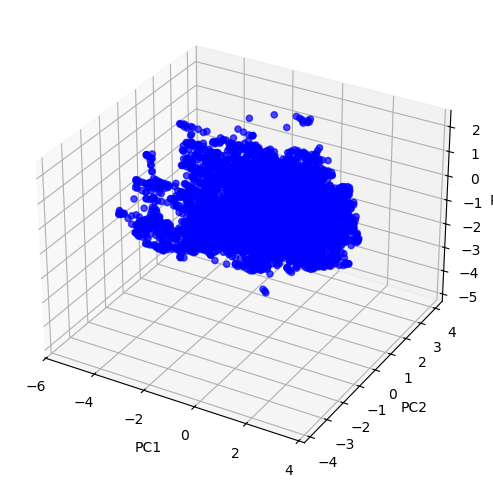

In [9]:
# Plot in the new space
"""
fig = px.scatter_3d(
                    x=Z[:, 0],
                    y=Z[:, 1],
                    z=Z[:, 2],
                    labels={'x': 'PC1', 'y': 'PC2', 'z': 'PC3'},
                    title='PCA 3D projection',
                    opacity=0.7
                )
fig.update_traces(marker=dict(size=3))
fig.show()
"""

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c='b', s=20, alpha=0.7)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.grid(True)
plt.show()

## DBSCAN

### Find the best parameters for the model

In [52]:
# Try different combinations of eps and num_of_samples
maxScore = -10
maxE = 0
maxM = 0
for i, EPS in enumerate(np.arange(0.01, 0.11, 0.01)):
    for j, M in enumerate(range(3, 10, 1)):
        dbs_model = DBSCAN(eps=EPS, min_samples=M).fit(Z)
        if len(np.unique(dbs_model.labels_)) > 1:
            silh = silhouette_score(Z, dbs_model.labels_)
        if silh > maxScore:
            maxScore = silh
            maxE = EPS
            maxM = M
print(f"Max score={maxScore} at ({maxE}, {maxM})")

Max score=-0.18467861193732726 at (0.03, 3)


C:\Users\javie\AppData\Local\Temp\ipykernel_19500\1994046722.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


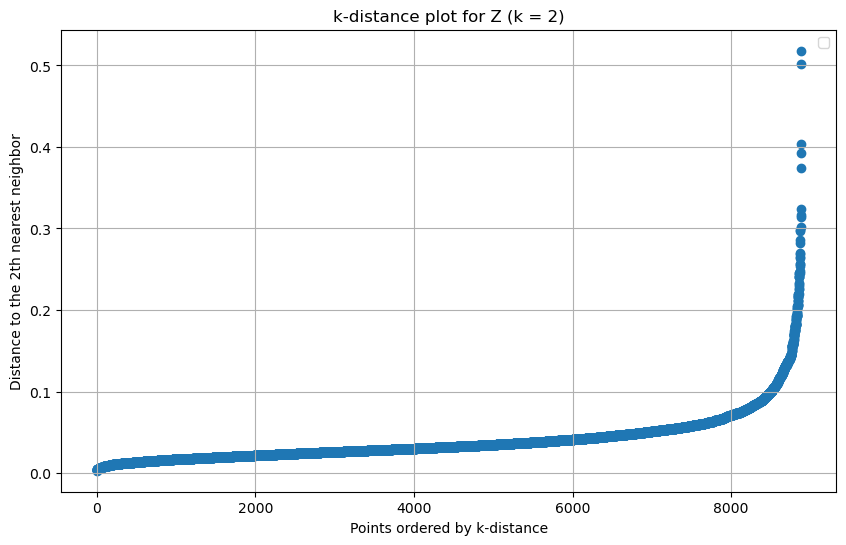

In [ ]:
# k-distance plot for k = 5
from sklearn.neighbors import NearestNeighbors

k = 3
nn = NearestNeighbors(n_neighbors=k + 1, metric='euclidean')
nn.fit(Z)
distances, _ = nn.kneighbors(Z)
# distances[:, 0] is the point itself; distances[:, -1] is the distance to the 5th nearest neighbor
k_distances = distances[:, -1]
sorted_idx = np.argsort(k_distances)
sorted_k_distances = k_distances[sorted_idx]


plt.figure(figsize=(10, 6))
plt.scatter(np.arange(len(sorted_k_distances)), sorted_k_distances)
plt.title(f'k-distance plot for Z (k = {k})')
plt.xlabel('Points ordered by k-distance')
plt.ylabel(f'Distance to the {k}th nearest neighbor')
plt.grid(True)
plt.legend()
plt.show()


In [62]:
# Let's use those best parameters for DBSCAN
dbs_model = DBSCAN(eps=0.03, min_samples=3).fit(Z)
print(f"DBSCAN cluster labels: {np.unique(dbs_model.labels_)}")

DBSCAN cluster labels: [ -1   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16
  17  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34
  35  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52
  53  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70
  71  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88
  89  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106
 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124
 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142
 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160
 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178
 179 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196
 197 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214
 215 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232
 233 234 235 236 237 238 239

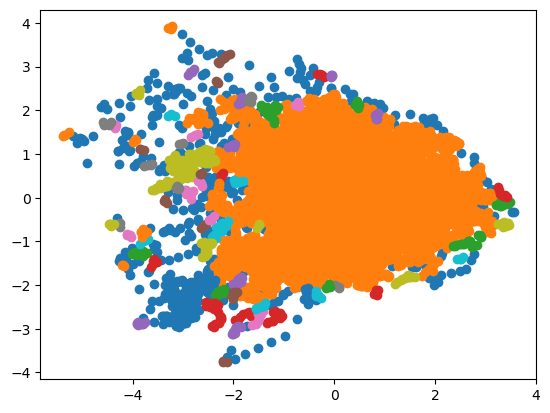

In [57]:
for c in np.unique(dbs_model.labels_):
    plt.scatter(Z[dbs_model.labels_==c, 0], Z[dbs_model.labels_==c, 1])
plt.show()

Epsilon is too high

In [63]:
silhouette_score(Z, dbs_model.labels_)

-0.18467861193732726

In [60]:
# Create a dataframe with the clustering data
clustering_data = pd.DataFrame(Z, columns= ['PC1', 'PC2'])
clustering_data['labels'] = dbs_model.labels_

##### Groups distribution

In [64]:
clustering_data[['labels','PC1']].groupby('labels').count()

,PC1
labels,
-1,282
0,7896
1,16
2,4
3,5
...,...
71,7
72,18
73,7
